# 01 Data exploration
Reproduces the main findings about the Amazon Fashion 2020 sample. Loading and validation come from `product_similarity`; this notebook only analyses and plots.
Each section ends with a check against the figure we expect, so a mismatch is visible.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from product_similarity.data import check_integrity, load_products
from product_similarity.validation import validate_products

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
archive = root / "data" / "archive.zip"
plt.rcParams.update(
    {"figure.figsize": (7, 3.5), "axes.spines.top": False, "axes.spines.right": False}
)

CHECKS = []


def check(name, actual, expected, tol=0.0):
    ok = abs(actual - expected) <= tol
    CHECKS.append((name, actual, expected, "match" if ok else "DIFFERS"))
    return ok

## 1. Source file and integrity

In [2]:
print("Archive matches the file supplied by SAP:", check_integrity(archive))
rows = load_products(archive)
df = pd.DataFrame(rows)
print(f"{len(df):,} rows, {df.shape[1]} columns")
check("rows", len(df), 30000)
check("columns", df.shape[1], 33)

Archive matches the file supplied by SAP: True


30,000 rows, 33 columns


True

### What this shows and what we do about it
**Integrity and size.** The archive is byte-identical to SAP's file, and the loader reads it in place. All 30,000 rows load and the 33 columns match, so later results can be traced to the original file.

## 2. Validation report

In [3]:
report = validate_products(rows)
print(report)
check("duplicate uniq_id", report.duplicate_uniq_ids, 0)
check("extra rows from repeated ASIN", report.duplicate_asin_extra_rows, 471)
check("weight sentinel rows", report.weight_sentinel_rows, 23745)
check("rows without price", report.rows_without_price, 2890)
check("rows without medium image", report.rows_without_image, 2)

ValidationReport(n_rows=30000, duplicate_uniq_ids=0, malformed_uniq_ids=0, missing_required={'uniq_id': 0, 'asin': 0, 'product_name': 0}, duplicate_asin_extra_rows=471, weight_sentinel_rows=23745, rows_without_image=2, rows_without_price=2890)


True

### What this shows and what we do about it
**Validation.** IDs are unique and well formed, so `uniq_id` is a safe API key. Repeated ASINs (471 extra rows) are recrawls, and 23,745 rows carry the weight placeholder.
**Decisions:** keep every `uniq_id` addressable but map repeated ASINs to one canonical record; treat `999999999` as missing instead of a number.

## 3. Missing values
Only fields with real values count as present (empty fields are absent in the source).

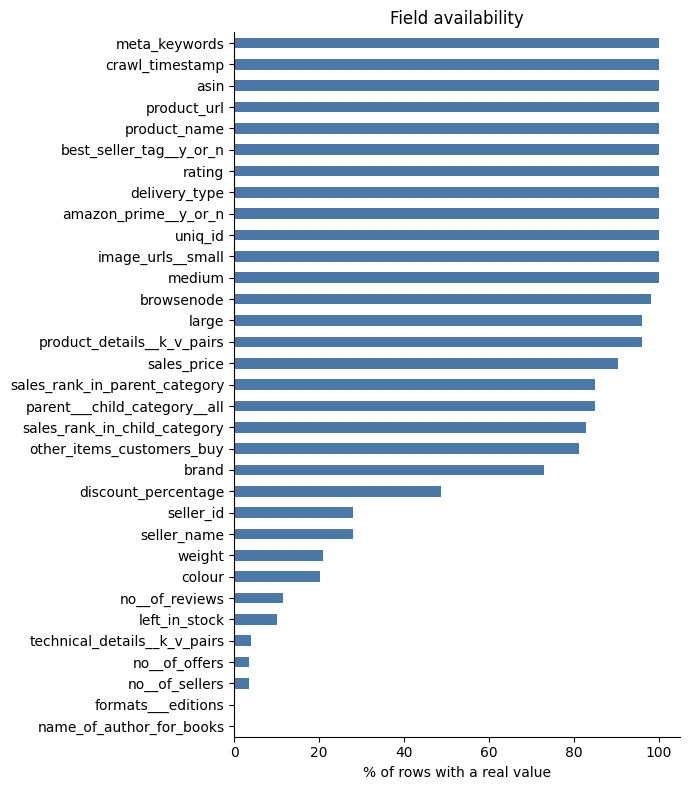

np.True_

In [4]:
present = df.notna().mean().mul(100).sort_values()
present["weight"] = (df["weight"] != "999999999").mean() * 100
present = present.sort_values()
ax = present.plot.barh(figsize=(7, 8), color="#4c78a8")
ax.set_xlabel("% of rows with a real value")
ax.set_title("Field availability")
plt.tight_layout()
plt.show()
check("brand % present", present["brand"], 72.86, 0.01)
check("sales_price % present", present["sales_price"], 90.37, 0.01)
check("colour % present", present["colour"], 20.10, 0.01)
check("weight % real", present["weight"], 20.85, 0.01)

### What this shows and what we do about it
**Availability.** Name, image and category are almost always present. Price (90%) and brand (73%) have gaps, and colour (20%) and real weight (21%) are mostly empty.
**Decisions:** build similarity around name, category, image, brand and price. Compare products only on attributes both have, instead of filling gaps with made-up values, which would create false similarity. Weight and colour get small weights.

## 4. Price
Strongly right-skewed, so a log scale is easier to read.

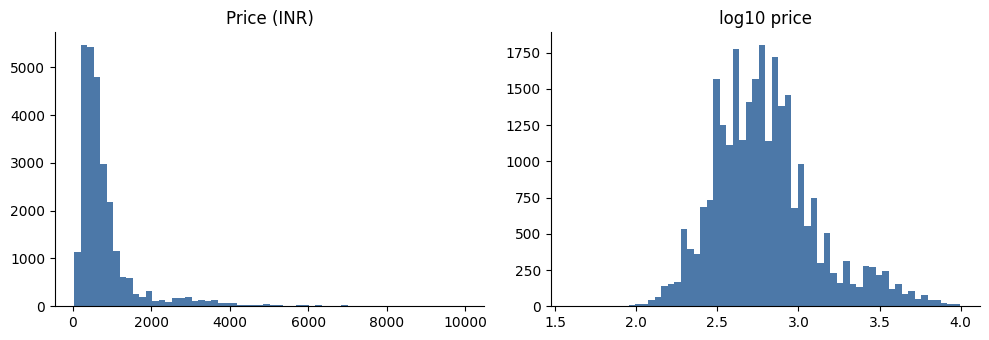

count    27110.0
mean       862.2
std        964.2
min         39.0
5%         219.0
25%        379.0
50%        590.0
75%        899.0
95%       2877.1
99%       5219.9
max       9988.0
Name: sales_price, dtype: float64


np.True_

In [5]:
price = df["sales_price"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(price, bins=60, color="#4c78a8")
axes[0].set_title("Price (INR)")
axes[1].hist(np.log10(price), bins=60, color="#4c78a8")
axes[1].set_title("log10 price")
plt.tight_layout()
plt.show()
print(price.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1))
check("price median", price.median(), 590, 0.5)
check("price mean", price.mean(), 862.17, 0.01)
check("price max", price.max(), 9988)

### What this shows and what we do about it
**Price.** Right-skewed: a few expensive items stretch the raw histogram, while the log version is close to symmetric.
**Decisions:** compare prices on a log scale so a Rs 300 vs Rs 600 gap counts like Rs 3,000 vs Rs 6,000. Whether to scale within a category is tested later in experiment E3, not assumed here.

## 5. Rating and review volume
Ratings of exactly 5.0 mostly come from products with very few reviews.

Rows saying 'Be the first to review' but carrying a rating: 6611
              rows  mean rating  % exactly 5.0
0                                             
none/unknown  7795         4.03          29.36
1             8065         4.32          49.97
2-9           9996         3.95          11.27
10-99         3696         3.73           0.11
100+           448         3.79           0.00


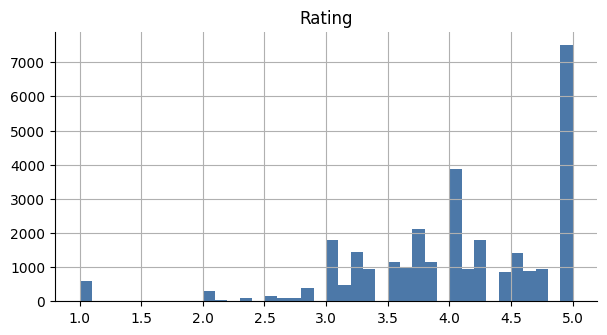

np.True_

In [6]:
reviews = df["product_details__k_v_pairs"].map(
    lambda d: d.get("Customer_Reviews", "") if isinstance(d, dict) else ""
)
count = reviews.str.extract(r"stars\s+([\d,]+)")[0].str.replace(",", "").astype(float)
bucket = pd.cut(
    count.fillna(0), [-1, 0, 1, 9, 99, 1e9], labels=["none/unknown", "1", "2-9", "10-99", "100+"]
)
no_reviews = reviews.str.startswith("Be the first")
print(
    "Rows saying 'Be the first to review' but carrying a rating:",
    int((no_reviews & df["rating"].notna()).sum()),
)
summary = df.groupby(bucket, observed=True)["rating"].agg(
    ["count", "mean", lambda s: (s == 5).mean() * 100]
)
summary.columns = ["rows", "mean rating", "% exactly 5.0"]
print(summary.round(2))
df["rating"].hist(bins=40, color="#4c78a8")
plt.title("Rating")
plt.show()
check("rated but no reviews", int((no_reviews & df["rating"].notna()).sum()), 6611)
check("rating mean", df["rating"].mean(), 4.04, 0.01)

### What this shows and what we do about it
**Rating.** Products with a single review are exactly 5.0 half the time, while products with 100+ reviews never are, and many rated products have no reviews at all.
**Decisions:** a raw rating mostly measures how few reviews a product has. Rating stays in the score because the brief names it, but with a small weight and adjusted by review count. Experiment E4 compares the options.

## 6. Weight
The placeholder `999999999` hides that few products have a real weight.

Real weights: 6,255 rows; parsed as grams: 6,234
Top 10 values: {'200 g': 736, '249 g': 689, '299 g': 398, '399 g': 304, '349 g': 259, '99.8 g': 251, '449 g': 228, '150 g': 190, '499 g': 168, '181 g': 163}
Top 20 values cover 69.1% of real weights


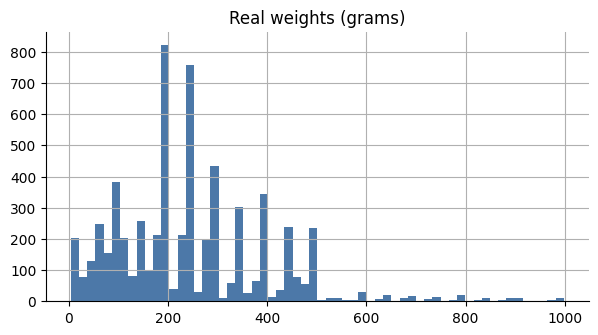

np.True_

In [7]:
real = df.loc[df["weight"] != "999999999", "weight"]
grams = pd.to_numeric(
    real.str.extract(r"^([\d.]+)\s*g(?:rams)?$", flags=2)[0], errors="coerce"
).dropna()
print(f"Real weights: {len(real):,} rows; parsed as grams: {len(grams):,}")
print("Top 10 values:", real.value_counts().head(10).to_dict())
share = real.value_counts().head(20).sum() / len(real) * 100
print(f"Top 20 values cover {share:.1f}% of real weights")
grams.hist(bins=60, color="#4c78a8")
plt.title("Real weights (grams)")
plt.show()
check("rows with real weight", len(real), 6255, 1)
check("top-20 weight share %", share, 69.0, 0.5)

### What this shows and what we do about it
**Weight.** Only about a fifth of rows have a real weight, and a handful of round values (200 g, 249 g, 299 g) cover most of them, which looks like default values.
**Decisions:** set the placeholder to missing, parse units, and reject implausible values. Weight stays in the score at a small weight, and experiment E2 shows whether it adds anything.

## 7. Repeated titles and ASINs

In [8]:
titles = df["product_name"].value_counts()
dup_rows = int(titles[titles > 1].sum())
print(f"{dup_rows:,} rows share an exact title with another row; most repeated:")
print(titles.head(5))
check("rows sharing a title", dup_rows, 10147)
check("distinct ASINs", df["asin"].nunique(), 29529)

10,147 rows share an exact title with another row; most repeated:
product_name
BIBA Women's Straight Kurta           70
W for Woman Straight Kurta            63
W for Woman Women's Straight Kurta    55
W for Women's Straight Kurta          47
Aurelia Women's Straight Kurta        43
Name: count, dtype: int64


True

### What this shows and what we do about it
**Repeats.** About a third of rows share an exact title with another row, mostly different products from the same brand, so text alone gives tied scores.
**Decisions:** text similarity needs other signals (category, image, brand, price), and ties get a fixed order. Whether near-identical variants should be collapsed is tested in experiment E11.

## 8. Categories

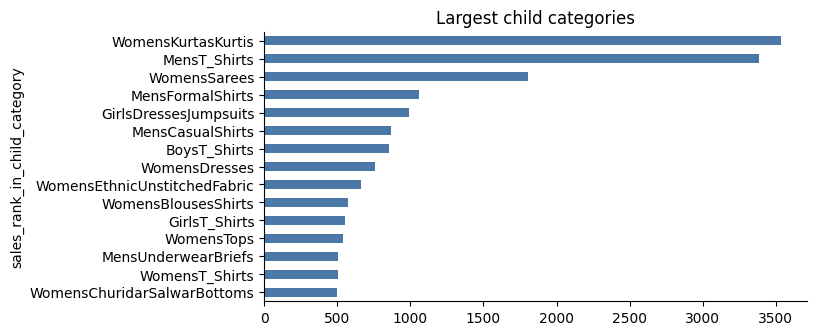

218 child categories, 144 with fewer than 20 rows
Category from child or browse node: 99.67%


np.True_

In [9]:
child = df["sales_rank_in_child_category"].map(
    lambda d: next(iter(d)) if isinstance(d, dict) and d else None
)
sizes = child.value_counts()
sizes.head(15).sort_values().plot.barh(color="#4c78a8")
plt.title("Largest child categories")
plt.show()
print(f"{len(sizes)} child categories, {int((sizes < 20).sum())} with fewer than 20 rows")
combined = (child.notna() | df["browsenode"].notna()).mean() * 100
print(f"Category from child or browse node: {combined:.2f}%")
check("categories under 20 rows", int((sizes < 20).sum()), 144)
check("category coverage %", combined, 99.67, 0.01)

### What this shows and what we do about it
**Categories.** A few categories hold most products, while more than half have fewer than 20 rows. Almost every product has a category from either field.
**Decisions:** category is the strongest structured signal, but a strict filter would leave rare categories with too few candidates, so we need a widening rule. Hard filter vs soft boost is tested in E12.

## 9. Images

count    29998.00
mean         4.20
std          1.82
min          1.00
25%          3.00
50%          4.00
75%          5.00
max         13.00
Name: medium, dtype: float64


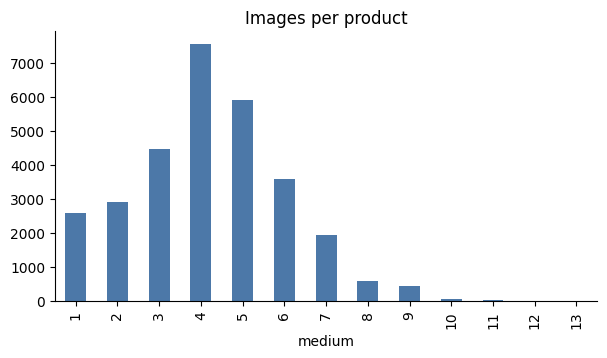

np.True_

In [10]:
n_img = df["medium"].dropna().map(lambda s: len(s.split("|")))
print(n_img.describe().round(2))
n_img.value_counts().sort_index().plot.bar(color="#4c78a8")
plt.title("Images per product")
plt.show()
check("rows with a medium image", int(df["medium"].notna().sum()), 29998)
check("median images", n_img.median(), 4)

### What this shows and what we do about it
**Images.** Nearly every product has at least one image, most have around four, and some have only one.
**Decisions:** image similarity is feasible, using the first image per product. Before downloading anything we check a small sample, because URLs being listed does not prove they work or show the right product.

## 10. Reproduction summary
Every figure from the earlier analysis that this notebook recomputes.

In [11]:
summary = pd.DataFrame(CHECKS, columns=["figure", "recomputed", "expected", "status"])
print(summary.to_string(index=False))
assert (summary["status"] == "match").all(), "Some figures differ from the earlier analysis"

                       figure   recomputed  expected status
                         rows 30000.000000  30000.00  match
                      columns    33.000000     33.00  match
            duplicate uniq_id     0.000000      0.00  match
extra rows from repeated ASIN   471.000000    471.00  match
         weight sentinel rows 23745.000000  23745.00  match
           rows without price  2890.000000   2890.00  match
    rows without medium image     2.000000      2.00  match
              brand % present    72.856667     72.86  match
        sales_price % present    90.366667     90.37  match
             colour % present    20.096667     20.10  match
                weight % real    20.850000     20.85  match
                 price median   590.000000    590.00  match
                   price mean   862.172397    862.17  match
                    price max  9988.000000   9988.00  match
         rated but no reviews  6611.000000   6611.00  match
                  rating mean     4.0398

## 11. Conclusion

**My goal** is simple: given a product, return the most similar products. Before building anything, I wanted to know how much I can trust each attribute in this dataset. So I loaded SAP's data straight from the original zip, validated it, plotted the main attributes, and recomputed 24 figures. All of them matched.

Here is what I found, and what I'm going to do about it. Each finding has a chart underneath that backs it up.

In [12]:
from IPython.display import display

BLUE, GREY, ORANGE = "#4c78a8", "#c7c7c7", "#f58518"
child_c = df["sales_rank_in_child_category"].map(
    lambda d: next(iter(d)) if isinstance(d, dict) and d else None
)

**First, name, category and image are almost always there.** Every product has them, so every comparison has something solid to work with. I'll use them as the main signals.

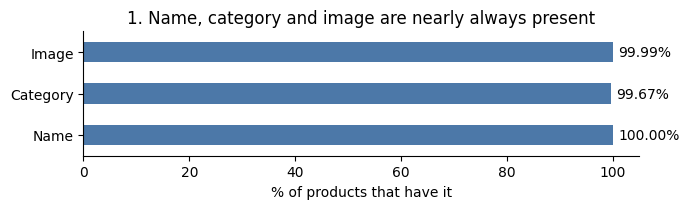

In [13]:
share = pd.Series(
    {
        "Name": df["product_name"].notna().mean() * 100,
        "Category": (child_c.notna() | df["browsenode"].notna()).mean() * 100,
        "Image": df["medium"].notna().mean() * 100,
    }
)
ax = share.plot.barh(color=BLUE, figsize=(7, 2.2))
ax.set_xlim(0, 105)
ax.set_xlabel("% of products that have it")
for i, v in enumerate(share):
    ax.text(v + 1, i, f"{v:.2f}%", va="center")
ax.set_title("1. Name, category and image are nearly always present")
plt.tight_layout()
plt.show()

**Second, brand and price are there for most products, but not all.** About 27% have no brand and 10% have no price. So I'll compare two products only on what they both have, and I won't fill gaps with made-up values.

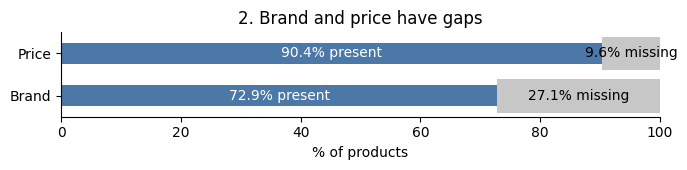

In [14]:
present = pd.Series(
    {"Brand": df["brand"].notna().mean() * 100, "Price": df["sales_price"].notna().mean() * 100}
)
ax = present.plot.barh(color=BLUE, figsize=(7, 1.8))
ax.barh(present.index, 100 - present.values, left=present.values, color=GREY)
for i, v in enumerate(present):
    ax.text(v / 2, i, f"{v:.1f}% present", va="center", ha="center", color="white")
    ax.text(v + (100 - v) / 2, i, f"{100 - v:.1f}% missing", va="center", ha="center")
ax.set_xlim(0, 100)
ax.set_xlabel("% of products")
ax.set_title("2. Brand and price have gaps")
plt.tight_layout()
plt.show()

**Third, price is skewed.** Most products cost around 590 rupees, but a few cost nearly 10,000, and those would dominate the comparison. So I'll compare prices by ratio, using a log scale. That way 300 versus 600 counts the same as 3,000 versus 6,000. I'll test this against other options before I finalize it.

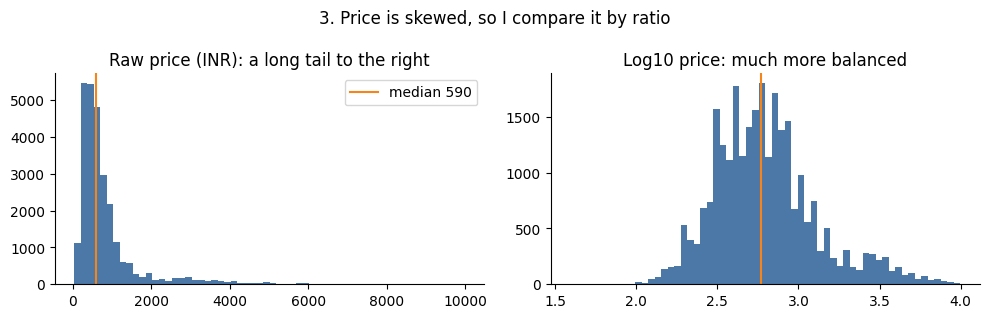

In [15]:
price_c = df["sales_price"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(price_c, bins=60, color=BLUE)
axes[0].axvline(price_c.median(), color=ORANGE, label=f"median {price_c.median():.0f}")
axes[0].set_title("Raw price (INR): a long tail to the right")
axes[0].legend()
axes[1].hist(np.log10(price_c), bins=60, color=BLUE)
axes[1].axvline(np.log10(price_c.median()), color=ORANGE)
axes[1].set_title("Log10 price: much more balanced")
fig.suptitle("3. Price is skewed, so I compare it by ratio")
plt.tight_layout()
plt.show()

**Fourth, weight is missing for about 79% of products.** Those rows hold a placeholder value, and the real weights are mostly round defaults like 200 grams. So I'll treat the placeholder as missing and give weight very little influence.

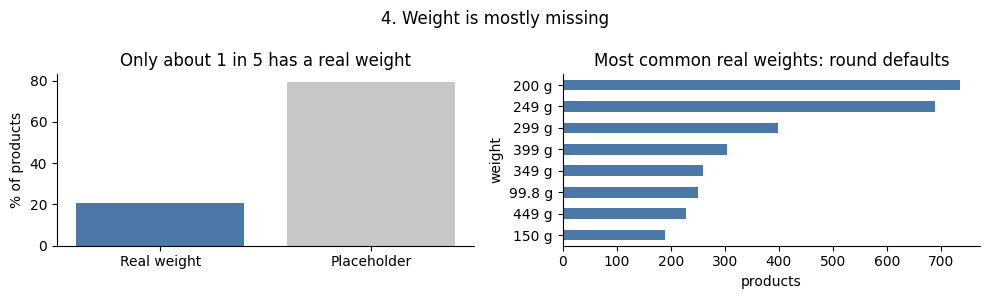

In [16]:
has_weight = df["weight"] != "999999999"
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].bar(
    ["Real weight", "Placeholder"],
    [has_weight.mean() * 100, (~has_weight).mean() * 100],
    color=[BLUE, GREY],
)
axes[0].set_ylabel("% of products")
axes[0].set_title("Only about 1 in 5 has a real weight")
top_w = df.loc[has_weight, "weight"].value_counts().head(8)
top_w.iloc[::-1].plot.barh(ax=axes[1], color=BLUE)
axes[1].set_title("Most common real weights: round defaults")
axes[1].set_xlabel("products")
fig.suptitle("4. Weight is mostly missing")
plt.tight_layout()
plt.show()

**Fifth, colour lists every option, not the product's own colour.** A shirt listed as "Black, Blue, Grey" doesn't tell me which one is in the photo. I'll read the real colour from the title instead, and treat the colour field as weak evidence once I've checked how accurate that is.

6,029 products have a colour value; every one lists at least 2 options.


,product_name,colour
0,Forest Club | Gym Wear | Sports Shorts| Shorts for Men | Smooth Br...,Black|Blue|Grey
1,PrintOctopus Graphic Printed T-Shirt for Men Chill T-Shirt | Hindi...,Black|Navy Blue
2,Miss Chase Women's Solid Shoulder Cut-Out Half-Sleeve Round Neck M...,Black|Maroon
3,PuJoy Women's Soft Cotton Traditional Bengali Handloom Jharna Desi...,Black Based|Black Based 2|Black White|Blue White|Green Based|Green...
4,kalpit creations Men's Comfort Soft Cotton Black Plain Polo Collar...,Black|Bottle green|GREEN|NAVY BLUE|Pink|Red|WHITE|blackk|gray|ligh...


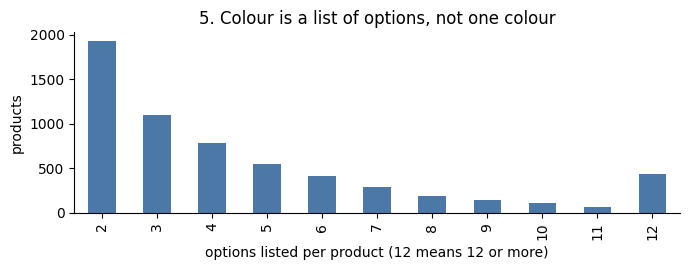

In [17]:
col = df.loc[df["colour"].notna(), ["product_name", "colour"]]
options = col["colour"].str.split("|").map(len)
print(
    f"{len(col):,} products have a colour value; every one lists at least {options.min()} options."
)
pd.set_option("display.max_colwidth", 70)
display(col.head(5).reset_index(drop=True))
ax = options.clip(upper=12).value_counts().sort_index().plot.bar(color=BLUE, figsize=(7, 2.8))
ax.set_xlabel("options listed per product (12 means 12 or more)")
ax.set_ylabel("products")
ax.set_title("5. Colour is a list of options, not one colour")
plt.tight_layout()
plt.show()

**Sixth, rating is unreliable.** A product with one review is a perfect 5.0 about half the time, while products with 100 or more reviews never are. And 6,611 products show a rating but have no reviews at all. So rating gets a small influence, adjusted by how many reviews it rests on. I'll test the exact method.

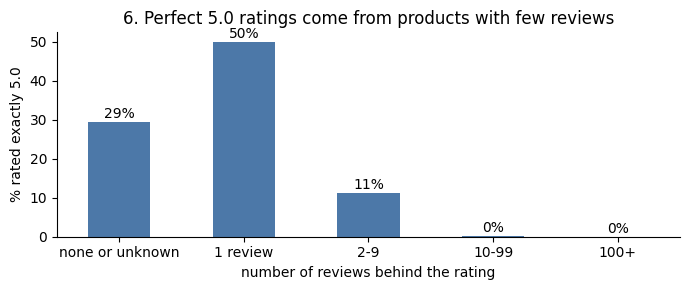

6,611 products show a rating but have no reviews.


In [18]:
page = df["product_details__k_v_pairs"].map(
    lambda d: d.get("Customer_Reviews", "") if isinstance(d, dict) else ""
)
n_rev = page.str.extract(r"stars\s+([\d,]+)")[0].str.replace(",", "").astype(float).fillna(0)
groups = pd.cut(
    n_rev,
    [-1, 0, 1, 9, 99, 1e9],
    labels=["none or unknown", "1 review", "2-9", "10-99", "100+"],
)
perfect = df.groupby(groups, observed=True)["rating"].apply(lambda s: (s == 5).mean() * 100)
ax = perfect.plot.bar(color=BLUE, figsize=(7, 3), rot=0)
for i, v in enumerate(perfect):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")
ax.set_xlabel("number of reviews behind the rating")
ax.set_ylabel("% rated exactly 5.0")
ax.set_title("6. Perfect 5.0 ratings come from products with few reviews")
plt.tight_layout()
plt.show()
rated_unreviewed = int((page.str.startswith("Be the first") & df["rating"].notna()).sum())
print(f"{rated_unreviewed:,} products show a rating but have no reviews.")

**Seventh, the same product appears more than once.** 471 extra rows are re-collected copies. I'll keep one record per product, accept every ID, and never return a product as its own match.

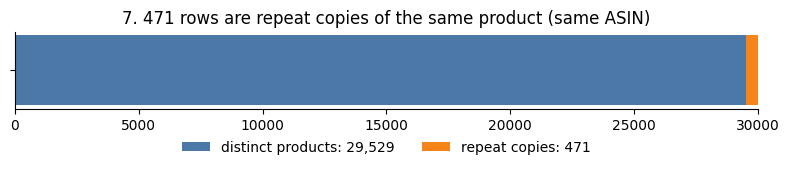

In [19]:
distinct = df["asin"].nunique()
repeats = len(df) - distinct
fig, ax = plt.subplots(figsize=(8, 2))
ax.barh([""], [distinct], color=BLUE, label=f"distinct products: {distinct:,}")
ax.barh([""], [repeats], left=[distinct], color=ORANGE, label=f"repeat copies: {repeats}")
ax.set_xlim(0, len(df))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
ax.set_title(f"7. {repeats} rows are repeat copies of the same product (same ASIN)")
plt.tight_layout()
plt.show()

**Eighth, many products share an identical title.** About a third do, so titles alone would give ties. I'll combine the title with category, image, brand and price, and break any remaining ties with a fixed rule.

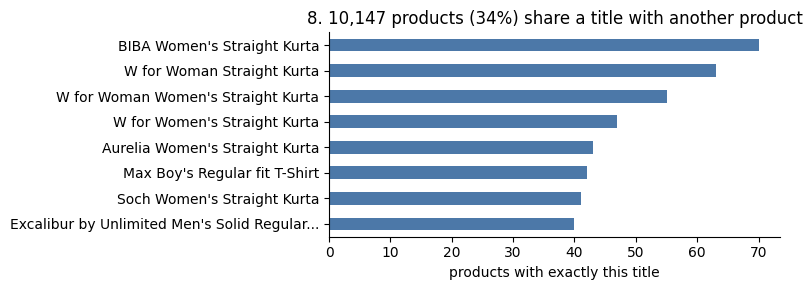

In [20]:
title_counts = df["product_name"].value_counts()
shared = int(title_counts[title_counts > 1].sum())
top_t = title_counts.head(8)
top_t.index = [t if len(t) <= 45 else t[:42] + "..." for t in top_t.index]
ax = top_t.iloc[::-1].plot.barh(color=BLUE, figsize=(8, 3))
ax.set_xlabel("products with exactly this title")
ax.set_title(f"8. {shared:,} products ({shared / len(df):.0%}) share a title with another product")
plt.tight_layout()
plt.show()

**Ninth, many categories are tiny.** 144 of the 218 categories have fewer than 20 products, so a strict category filter would leave too few results. I'll use category as a strong hint, not a hard filter, and test that.

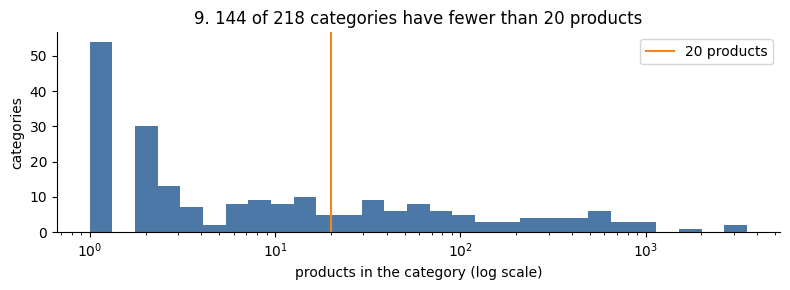

In [21]:
cat_sizes = child_c.value_counts()
small = int((cat_sizes < 20).sum())
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(cat_sizes, bins=np.logspace(0, np.log10(cat_sizes.max()), 30), color=BLUE)
ax.set_xscale("log")
ax.axvline(20, color=ORANGE, label="20 products")
ax.set_xlabel("products in the category (log scale)")
ax.set_ylabel("categories")
ax.legend()
ax.set_title(f"9. {small} of {len(cat_sizes)} categories have fewer than 20 products")
plt.tight_layout()
plt.show()

**Tenth, I haven't checked the images yet.** The links exist, and about 99% of a 300-link sample worked, but I haven't looked at the pictures. I'll review a small sample first and download the rest only after that.

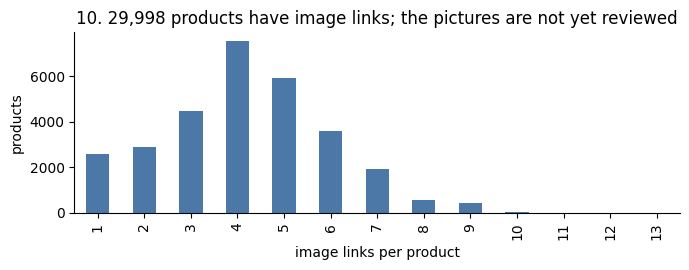

The 300-link availability check was run separately, because it needs internet access.


In [22]:
per_product = df["medium"].dropna().map(lambda s: len(s.split("|")))
ax = per_product.value_counts().sort_index().plot.bar(color=BLUE, figsize=(7, 2.8))
ax.set_xlabel("image links per product")
ax.set_ylabel("products")
ax.set_title(
    f"10. {len(per_product):,} products have image links; the pictures are not yet reviewed"
)
plt.tight_layout()
plt.show()
print("The 300-link availability check was run separately, because it needs internet access.")

**Overall,** the dataset is complete enough to build similarity around product name, category and image, with brand and price as supporting signals. Weight, colour and rating are too incomplete or unreliable to lead, so they'll carry little influence. Repeated products, repeated titles and missing values are the main risks, and each has a planned fix. The data tells me how much to trust each attribute, but it can't tell me which products shoppers consider similar. I'll measure that with a small set of manually judged examples.

**Next,** I'll write the preprocessing code to clean weight, brand, category, colour and duplicates. Then I'll build a first working similarity function, followed by the API and the Docker image. After that, I'll check the images and run experiments on the open choices.